# Validating the models

**Goal:** Check if the results from the 80/20 split can be trusted. This notebook reads the reported results and does not retrain anything.

- **Headline results:** one random 80/20 split (seed 42)
- **5-fold cross-validation:** how much the scores move between splits
- **Leave-one-throttle-out:** each fold tests on a lever position never seen in training

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.read_csv("../reports/model_results.csv", index_col=0)
random_cv = pd.read_csv("../reports/cv_random_folds.csv")
throttle_cv = pd.read_csv("../reports/cv_held_out_throttle.csv")

results

,compressor_rmse,turbine_rmse,compressor_mae,turbine_mae,compressor_improvement_pct,turbine_improvement_pct
baseline,0.01467,0.00755,0.01272,0.00654,0.00000,0.00000
linear regression,0.00687,0.00343,0.00568,0.00267,53.12747,54.53890
decision tree,0.00160,0.00129,0.00112,0.00080,89.08421,82.87841
random forest,0.00087,0.00065,0.00047,0.00033,94.08643,91.45625
xgboost,0.00116,0.00091,0.00087,0.00063,92.07043,87.93576


### 5-fold cross-validation

Each row is tested once, so there are 5 scores per model. The bars are the mean and the lines are the standard deviation across folds.

The means are close to the headline numbers and the standard deviation is small compared to the differences in the models, so the model ranking is stable.

                  compressor_rmse          turbine_rmse         
                             mean      std         mean      std
model                                                           
baseline                  0.01472  0.00007      0.00750  0.00008
linear regression         0.00695  0.00007      0.00348  0.00011
decision tree             0.00173  0.00015      0.00142  0.00015
random forest             0.00096  0.00009      0.00076  0.00009
xgboost                   0.00123  0.00005      0.00092  0.00005


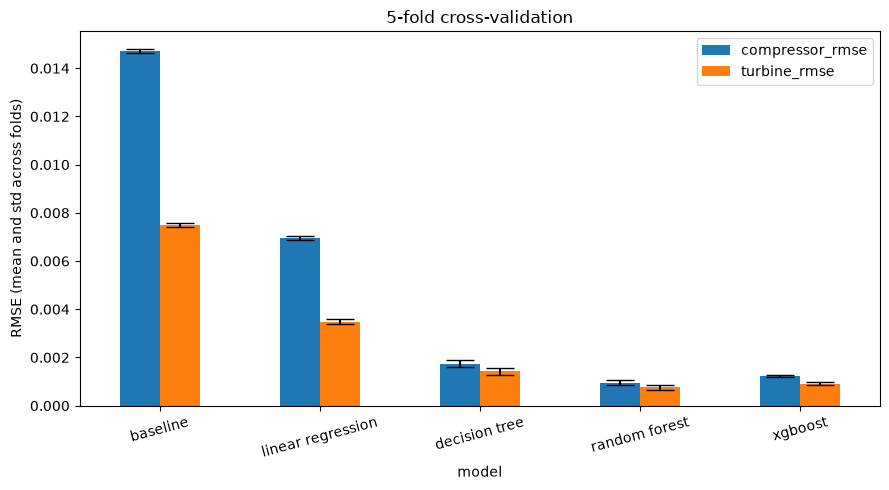

In [12]:
cols = ["compressor_rmse", "turbine_rmse"]
grouped = random_cv.groupby("model", sort=False)[cols]

print(grouped.agg(["mean", "std"]).round(5))

ax = grouped.mean().plot.bar(yerr=grouped.std(), capsize=10, figsize=(9, 5), rot=15)
ax.set_ylabel("RMSE (mean and std across folds)")
ax.set_title("5-fold cross-validation")
plt.tight_layout()
plt.savefig("../reports/figures/08_cv_random_folds.png", dpi=150, bbox_inches="tight")

### Random folds vs unseen throttle settings

The left bar chart looks at compressor wear and each model's mean RMSE. The right bar chart looks at turbine wear and each model's mean RMSE. The scale is logarithmic so small and large errors both fit.

The model's error is high when the lever position is held out, and all of models with the unseen throttle are around the same increased RMSE value. However, this means that they got worse by different amounts, with the tree and forest model having the most drastic increase.

It also means that the random-split results are overly optimistic because the models are memorizing known throttle settings rather than learning true engine wear. With a random split, the models interpolate between similar operating conditions seen during training. Once a throttle setting is held out, every model fails to extrapolate due to the missing setting and drop to baseline-level error or higher.

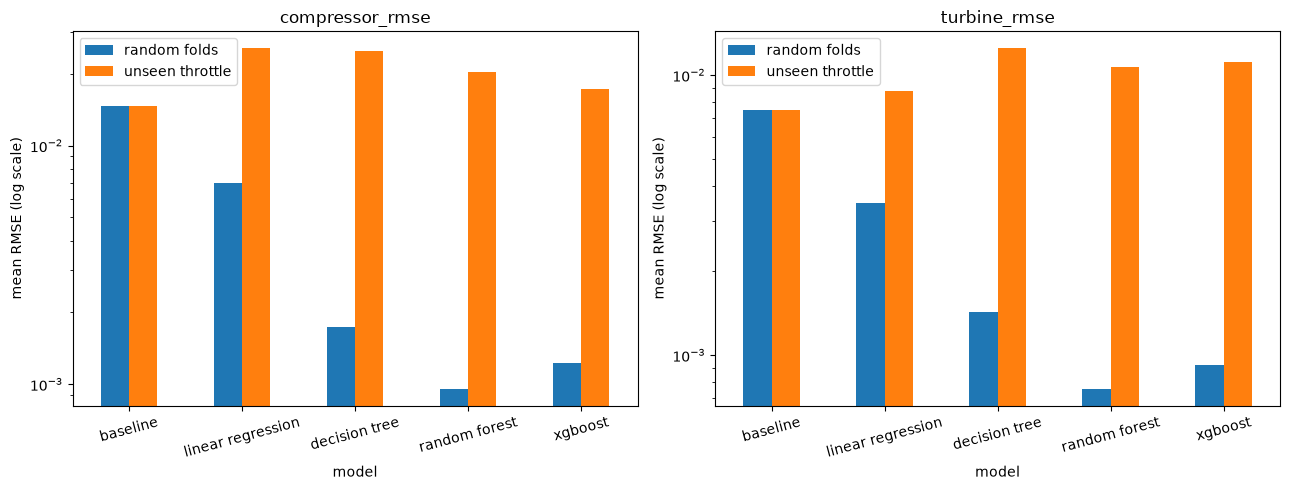

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, col in zip(axes, ["compressor_rmse", "turbine_rmse"]):
    compare = pd.DataFrame({
        "random folds": random_cv.groupby("model", sort=False)[col].mean(),
        "unseen throttle": throttle_cv.groupby("model", sort=False)[col].mean(),
    })
    compare.plot.bar(ax=ax, rot=15, logy=True)
    ax.set_title(col)
    ax.set_ylabel("mean RMSE (log scale)")

plt.tight_layout()
plt.savefig("../reports/figures/09_random_vs_unseen_throttle.png", dpi=150, bbox_inches="tight")

### Error by held-out throttle setting

Each point is one fold. The models were trained on the other 8 lever positions and tested on the held-out one.

Most of the models held out relatively similarily to the other, but the linear regression model has an erratic RMSE. It changed on every level position with no clear pattern.

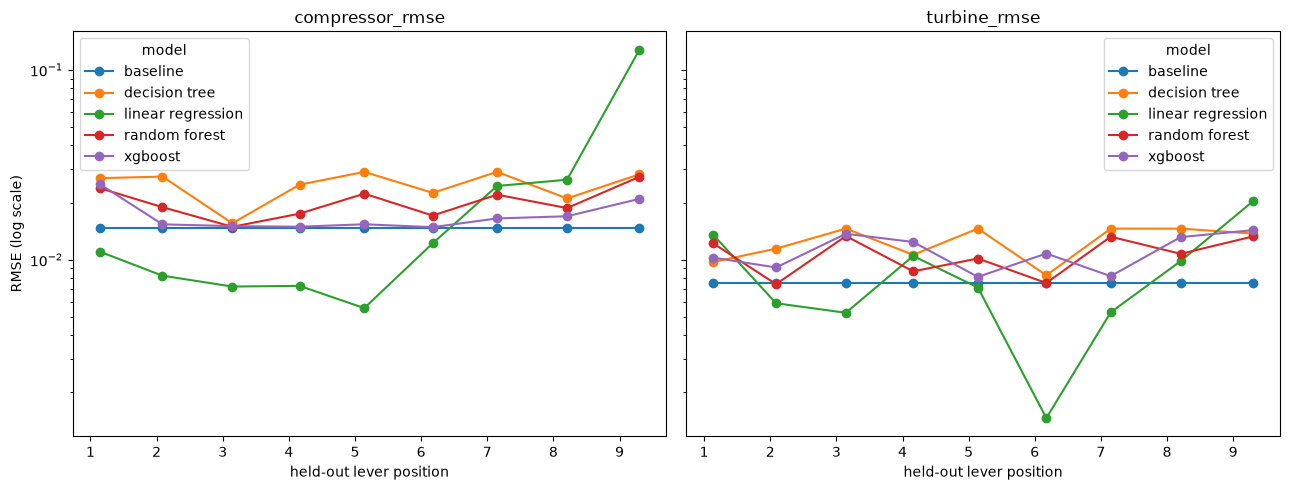

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, col in zip(axes, ["compressor_rmse", "turbine_rmse"]):
    by_throttle = throttle_cv.pivot(index="held_out_lever", columns="model", values=col)
    by_throttle.plot(ax=ax, marker="o", logy=True)
    ax.set_title(col)
    ax.set_xlabel("held-out lever position")
    ax.set_ylabel("RMSE (log scale)")

plt.tight_layout()
plt.savefig("../reports/figures/10_error_by_unseen_throttle.png", dpi=150, bbox_inches="tight")

### Training and prediction time

Average seconds per fold on my computer. The forest and XGBoost use all CPU cores.

The random forest model took the longest to train, with its fit time being more than double of XGBoost's time and more than quadruple of the other models. For its predict time, it took roughly 8 times longer than XGBoost and 20 times longer than the other models.

Random forest has the least error and highest improvement (compared to the baseline) among the models, but XGBoost trailed behind by about 2% for compressor improvement and 3.5% for turbine improvement. XGBoost is the better model when dealing with large amounts of data and testing due to its speeds, but if a low error is priority, it would be best to use a random forest model.

In [16]:
random_cv.groupby("model", sort=False)[["fit_seconds", "predict_seconds"]].mean()

,fit_seconds,predict_seconds
model,,
baseline,0.006786,0.000172
linear regression,0.009813,0.001937
decision tree,0.161045,0.002075
random forest,0.834022,0.079794
xgboost,0.296853,0.009011
